In [29]:
import pandas as pd

foxconndf= pd.read_csv('./stock.csv')
foxconndf.dropna(how='any',inplace=True)

foxconndf_k= pd.read_csv('./stock_k.csv')
foxconndf_k.dropna(how='any',inplace=True)

inner = pd.merge(left=foxconndf,right=foxconndf_k,how="inner")

inner = inner.drop(['date','stock_id','Trading_money','spread','Trading_turnover','Foreign_Dealer_Self_buy','Foreign_Dealer_Self_sell'], axis=1)

inner = inner.fillna(0.0)


In [30]:
from sklearn import preprocessing

def normalize(df):
    newdf= df.copy()
    min_max_scaler = preprocessing.MinMaxScaler()

    newdf['open'] = min_max_scaler.fit_transform(df.open.values.reshape(-1,1))
    newdf['Trading_Volume'] = min_max_scaler.fit_transform(df.Trading_Volume.values.reshape(-1,1))
    newdf['close'] = min_max_scaler.fit_transform(df.close.values.reshape(-1,1))
    newdf['Max'] = min_max_scaler.fit_transform(df.Max.values.reshape(-1,1))
    newdf['Min'] = min_max_scaler.fit_transform(df.Min.values.reshape(-1,1))

    newdf['Foreign_Investor_buy'] = min_max_scaler.fit_transform(df.Foreign_Investor_buy.values.reshape(-1,1))
    newdf['Foreign_Investor_sell'] = min_max_scaler.fit_transform(df.Foreign_Investor_sell.values.reshape(-1,1))
    newdf['Investment_Trust_buy'] = min_max_scaler.fit_transform(df.Investment_Trust_buy.values.reshape(-1,1))
    newdf['Investment_Trust_sell'] = min_max_scaler.fit_transform(df.Investment_Trust_sell.values.reshape(-1,1))
    newdf['Dealer_self_buy'] = min_max_scaler.fit_transform(df.Dealer_self_buy.values.reshape(-1,1))
    newdf['Dealer_self_sell'] = min_max_scaler.fit_transform(df.Dealer_self_sell.values.reshape(-1,1))
    newdf['Dealer_Hedging_buy'] = min_max_scaler.fit_transform(df.Dealer_Hedging_buy.values.reshape(-1,1))
    newdf['Dealer_Hedging_sell'] = min_max_scaler.fit_transform(df.Dealer_Hedging_sell.values.reshape(-1,1))
    
    return newdf

foxconndf_norm= normalize(inner.reindex(columns=['Foreign_Investor_buy','Foreign_Investor_sell','Investment_Trust_buy','Investment_Trust_sell','Dealer_self_buy','Dealer_self_sell','Dealer_Hedging_buy','Dealer_Hedging_sell','Trading_Volume','Max','Min','open','close']))



In [31]:
import numpy as np

def data_helper(df, time_frame):
    

    number_features = len(df.columns)


    datavalue = df.values

    result = []

    for index in range( len(datavalue) - (time_frame+1) ):
        result.append(datavalue[index: index + (time_frame+1) ]) 
    
    result = np.array(result)
    number_train = round(0.9 * result.shape[0]) 
    
    x_train = result[:int(number_train), :-1] 
    y_train = result[:int(number_train), -1][:,-1] 
    

    x_test = result[int(number_train):, :-1]
    x_test_open = result[int(number_train):, :-1][:,-1]
    y_test = result[int(number_train):, -1][:,-1]

    x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], number_features))
    x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], number_features))  

    return [x_train, y_train, x_test, y_test , x_test_open]


X_train, y_train, X_test, y_test  , x_test_open= data_helper(foxconndf_norm, 1)

In [32]:
from keras.models import Sequential
from keras.layers.core import Dense, Dropout, Activation
from keras.layers import LSTM
import keras

def build_model(input_length, input_dim):
    d = 0.3
    model = Sequential()

    model.add(LSTM(256, input_shape=(input_length, input_dim), return_sequences=True))
    model.add(Dropout(d))

    model.add(LSTM(256, input_shape=(input_length, input_dim), return_sequences=False))
    model.add(Dropout(d))

    model.add(Dense(16,kernel_initializer="uniform",activation='relu'))
    model.add(Dense(1,kernel_initializer="uniform",activation='linear'))

    model.compile(loss='mse',optimizer='adam', metrics=['accuracy'])

    return model


model = build_model(1 , 13)


history = model.fit( X_train, y_train, batch_size=128, epochs=50, validation_split=0.1, verbose=1)


Epoch 1/50
9/9 [==============================] - 4s 100ms/step - loss: 0.1430 - accuracy: 9.3371e-04 - val_loss: 0.4042 - val_accuracy: 0.0000e+00
Epoch 2/50
9/9 [==============================] - 0s 14ms/step - loss: 0.1325 - accuracy: 9.3371e-04 - val_loss: 0.3681 - val_accuracy: 0.0000e+00
Epoch 3/50
9/9 [==============================] - 0s 14ms/step - loss: 0.1083 - accuracy: 9.3371e-04 - val_loss: 0.2645 - val_accuracy: 0.0000e+00
Epoch 4/50
9/9 [==============================] - 0s 13ms/step - loss: 0.0524 - accuracy: 9.3371e-04 - val_loss: 0.0488 - val_accuracy: 0.0000e+00
Epoch 5/50
9/9 [==============================] - 0s 15ms/step - loss: 0.0204 - accuracy: 9.3371e-04 - val_loss: 0.0056 - val_accuracy: 0.0000e+00
Epoch 6/50
9/9 [==============================] - 0s 14ms/step - loss: 0.0131 - accuracy: 9.3371e-04 - val_loss: 0.0446 - val_accuracy: 0.0000e+00
Epoch 7/50
9/9 [==============================] - 0s 14ms/step - loss: 0.0113 - accuracy: 9.3371e-04 - val_loss: 0.01

In [33]:
def denormalize(df, norm_value):
    original_value = df['close'].values.reshape(-1,1)
    norm_value = norm_value.reshape(-1,1)
    
    min_max_scaler = preprocessing.MinMaxScaler()
    min_max_scaler.fit_transform(original_value)
    denorm_value = min_max_scaler.inverse_transform(norm_value)
    
    return denorm_value


pred = model.predict(X_test)



denorm_pred = denormalize(inner, pred)
denorm_ytest = denormalize(inner, y_test)
denorm_xtest = denormalize(inner , x_test_open)

5/5 [==============================] - 1s 2ms/step


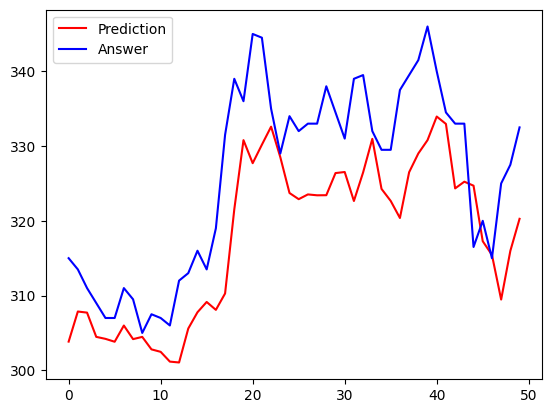

In [34]:
import matplotlib.pyplot as plt
%matplotlib inline  

plt.plot(denorm_pred[:50],color='red', label='Prediction')
plt.plot(denorm_ytest[:50],color='blue', label='Answer')
plt.legend(loc='best')
plt.show()

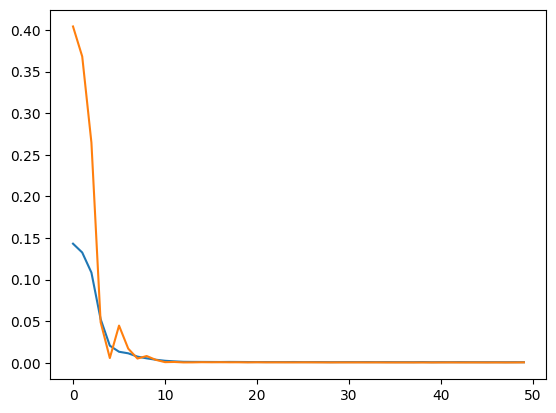

In [35]:
train_loss = history.history['loss']
val_loss   = history.history['val_loss']
xc         = range(50)
 
plt.figure()
plt.plot(xc, train_loss)
plt.plot(xc, val_loss)